In [1]:
using Plots
using Distributions, Random, Statistics
using LinearAlgebra, SparseArrays, JSON
using Colors, Dates
using CSV
using DataFrames

In [ ]:
# Features: windspeed_10m, windspeed_100m, windgusts_10m
# adding feature transformation to all additional features,
# while keeping a weight applied to each feature


purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

# Load three training datasets
data1 = CSV.read("Location1.csv", DataFrame)   
data2 = CSV.read("Location2.csv", DataFrame)  # ADDED
data3 = CSV.read("Location3.csv", DataFrame)  # ADDED

data1.Time = DateTime.(data1.Time)  # ADDED
data2.Time = DateTime.(data2.Time)  # ADDED
data3.Time = DateTime.(data3.Time)  # ADDED

# Combine training datasets
data = vcat(data1, data2, data3)  # ADDED

n = nrow(data)  # CHANGED
sort_index = sortperm(data.Time)  # CHANGED

t = Float64.(data.Power[sort_index])

wind10_raw = Float64.(data.windspeed_10m[sort_index])
wind100_raw = Float64.(data.windspeed_100m[sort_index])
windgust_raw = Float64.(data.windgusts_10m[sort_index])

time = data.Time[sort_index]

# Normalize all three features
x = wind10_raw ./ 10.0
z = wind100_raw ./ 10.0
windgust = windgust_raw ./ 10.0

hour = Float64.(Dates.hour.(time))
hour_sin = sin.(2π .* hour ./ 24.0)
hour_cos = cos.(2π .* hour ./ 24.0)

α = 0.01
iter_max = 25_000
λ = 0.01
reg_type = "l2"

c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

# Gaussian RBF transformation
function φ(x_value, j)
    return exp(-(γ * abs(x_value - c[j]))^2)
end

Φ_10 = zeros(n, num_centers)
Φ_100 = zeros(n, num_centers)
Φ_gust = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ_10[i, j] = φ(x[i], j)
        Φ_100[i, j] = φ(z[i], j)
        Φ_gust[i, j] = φ(windgust[i], j)
    end
end

Random.seed!(128)

w_0 = rand()

# RBF weights
w_10 = rand(num_centers)
w_100 = rand(num_centers)
w_gust = rand(num_centers)

# Feature weights
β_100 = rand()
β_windgust = rand()

# Stochastic gradient descent
for iteration in 1:iter_max

    i = rand(1:n)

    ϕ10_i = Φ_10[i, :]
    ϕ100_i = Φ_100[i, :]
    ϕgust_i = Φ_gust[i, :]

    # RBF contribution from each feature
    f_10 = dot(ϕ10_i, w_10)
    f_100 = dot(ϕ100_i, w_100)
    f_gust = dot(ϕgust_i, w_gust)

    y_hat = w_0 +
            f_10 +
            β_100 * f_100 +
            β_windgust * f_gust

    error = y_hat - t[i]

    # Bias
    w_0 -= α * error
    # RBF weights for windspeed_10m
    for j in 1:num_centers
        w_10[j] -= α * error * ϕ10_i[j]
    end
    # RBF weights for windspeed_100m
    for j in 1:num_centers
        w_100[j] -= α * error * β_100 * ϕ100_i[j]
    end
    # RBF weights for windgusts_10m
    for j in 1:num_centers
        w_gust[j] -= α * error * β_windgust * ϕgust_i[j]
    end
    # Feature weights
    β_100 -= α * error * f_100
    β_windgust -= α * error * f_gust

    if reg_type == "l2"

        w_10 .-= α * λ .* w_10
        w_100 .-= α * λ .* w_100
        w_gust .-= α * λ .* w_gust

        β_100 -= α * λ * β_100
        β_windgust -= α * λ * β_windgust

    elseif reg_type == "l1"

        w_10 .= sign.(w_10) .* max.(0, abs.(w_10) .- α * λ)
        w_100 .= sign.(w_100) .* max.(0, abs.(w_100) .- α * λ)
        w_gust .= sign.(w_gust) .* max.(0, abs.(w_gust) .- α * λ)

        β_100 = sign(β_100) * max(0, abs(β_100) - α * λ)
        β_windgust = sign(β_windgust) * max(0, abs(β_windgust) - α * λ)

    end

end

function w̅(x_value, z_value, windgust_value)

    f_10 = sum(w_10[j] * φ(x_value, j)
               for j in 1:num_centers)
    f_100 = sum(w_100[j] * φ(z_value, j)
                for j in 1:num_centers)
    f_gust = sum(w_gust[j] * φ(windgust_value, j)
                 for j in 1:num_centers)

    return w_0 +
           f_10 +
           β_100 * f_100 +
           β_windgust * f_gust
end


prediction = w_0 .+ Φ_10 * w_10 .+ β_100 .* (Φ_100 * w_100) .+ β_windgust .* (Φ_gust * w_gust)

# Model performance
errors = prediction .- t

RMSE = sqrt(mean(errors.^2))
MAE = mean(abs.(errors))

println()
println("========== MODEL PERFORMANCE ==========")
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("β_100 = ", β_100)
println("β_windgust = ", β_windgust)
println("=======================================")


========== MODEL PERFORMANCE ==========
RMSE = 0.21590826414228445
MAE  = 0.17483775606276503
β_100 = -0.3254268581352606
β_windgust = -0.22355558905140438


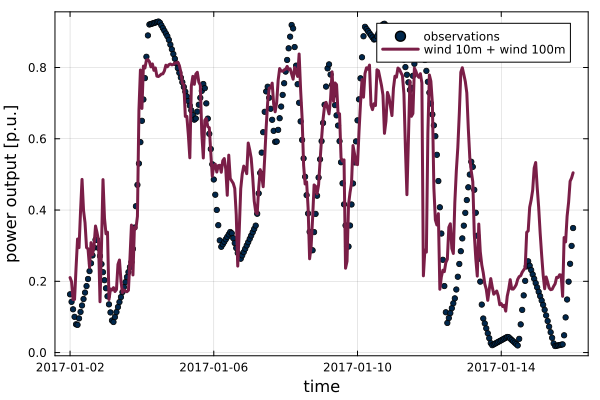

In [5]:
two_weeks = time .<= (time[1] + Day(14))
time_2wk = time[two_weeks]
t_2wk = t[two_weeks]
prediction_2wk = prediction[two_weeks]

plo = scatter(time_2wk,t_2wk,c=blue,frame=:box,label="observations",xlabel="time",ylabel="power output [p.u.]",markersize=3)
plot!(plo,time_2wk,prediction_2wk,lw=3,c=purple,label="wind 10m + wind 100m")

display(plo)

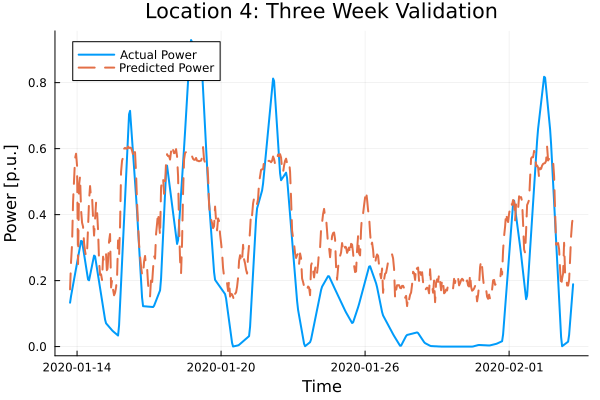


======= VALIDATION PERFORMANCE =======
Validation RMSE = 0.17232332042501863
Validation period: 2020-01-13T17:00:00 to 2020-02-03T16:00:00


In [21]:
# Load validation data
validation_data = CSV.read("Location4.csv", DataFrame)

validation_data.Time = DateTime.(validation_data.Time)
validation_sort_index = sortperm(validation_data.Time)
validation_data = validation_data[validation_sort_index, :]

n_validation = min(504, nrow(validation_data))
start_index = rand(1:(nrow(validation_data) - n_validation + 1))
end_index = start_index + n_validation - 1

validation_time = validation_data.Time[start_index:end_index]
validation_power = Float64.(validation_data.Power[start_index:end_index])

validation_wind10 = Float64.(validation_data.windspeed_10m[start_index:end_index]) ./ 10.0
validation_wind100 = Float64.(validation_data.windspeed_100m[start_index:end_index]) ./ 10.0
validation_windgust = Float64.(validation_data.windgusts_10m[start_index:end_index]) ./ 10.0

Φ_validation_10 = zeros(n_validation, num_centers)
Φ_validation_100 = zeros(n_validation, num_centers)
Φ_validation_gust = zeros(n_validation, num_centers)

for i in 1:n_validation
    for j in 1:num_centers
        Φ_validation_10[i, j] = φ(validation_wind10[i], j)
        Φ_validation_100[i, j] = φ(validation_wind100[i], j)
        Φ_validation_gust[i, j] = φ(validation_windgust[i], j)
    end
end

validation_prediction =
    w_0 .+
    Φ_validation_10 * w_10 .+
    β_100 .* (Φ_validation_100 * w_100) .+
    β_windgust .* (Φ_validation_gust * w_gust)

validation_errors = validation_prediction .- validation_power

validation_RMSE = sqrt(mean(validation_errors.^2))

println()
println("======= VALIDATION PERFORMANCE =======")
println("Validation RMSE = ", validation_RMSE)
println("Validation period: ", validation_time[1], " to ", validation_time[end])
println("=====================================")

p_validation = plot(validation_time, validation_power, lw=2, label="Actual Power", xlabel="Time", ylabel="Power [p.u.]", title="Location 4: Three Week Validation")
plot!(p_validation, validation_time, validation_prediction, lw=2, linestyle=:dash, label="Predicted Power")

display(p_validation)

In [ ]:
# Features: windspeed_10m, windspeed_100m, windgusts_10m, winddirection_10m, winddirection_10m
# Feature transformations applied to all additional features,
# while keeping a weight applied to each feature

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

# Load three training datasets
data1 = CSV.read("Location1.csv", DataFrame)
data2 = CSV.read("Location2.csv", DataFrame)
data3 = CSV.read("Location3.csv", DataFrame)

data1.Time = DateTime.(data1.Time)
data2.Time = DateTime.(data2.Time)
data3.Time = DateTime.(data3.Time)

# Combine training datasets
data = vcat(data1, data2, data3)

n = nrow(data)
sort_index = sortperm(data.Time)

t = Float64.(data.Power[sort_index])

wind10_raw = Float64.(data.windspeed_10m[sort_index])
wind100_raw = Float64.(data.windspeed_100m[sort_index])
windgust_raw = Float64.(data.windgusts_10m[sort_index])
winddirection_raw = Float64.(data.winddirection_10m[sort_index])

time = data.Time[sort_index]

# Normalize wind speed features
x = wind10_raw ./ 10.0
z = wind100_raw ./ 10.0
windgust = windgust_raw ./ 10.0

# Circular transformation of wind direction
winddirection_sin = sin.(2π .* winddirection_raw ./ 360.0)
winddirection_cos = cos.(2π .* winddirection_raw ./ 360.0)

hour = Float64.(Dates.hour.(time))
hour_sin = sin.(2π .* hour ./ 24.0)
hour_cos = cos.(2π .* hour ./ 24.0)

α = 0.01
iter_max = 25_000
λ = 0.01
reg_type = "l2"

c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

# Gaussian RBF transformation
function φ(x_value, j)
    return exp(-(γ * abs(x_value - c[j]))^2)
end

Φ_10 = zeros(n, num_centers)
Φ_100 = zeros(n, num_centers)
Φ_gust = zeros(n, num_centers)

# Separate RBF transformations for circular wind direction
Φ_direction_sin = zeros(n, num_centers)
Φ_direction_cos = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ_10[i, j] = φ(x[i], j)
        Φ_100[i, j] = φ(z[i], j)
        Φ_gust[i, j] = φ(windgust[i], j)

        Φ_direction_sin[i, j] = φ(winddirection_sin[i], j)
        Φ_direction_cos[i, j] = φ(winddirection_cos[i], j)
    end
end

Random.seed!(128)

w_0 = rand()

# RBF weights
w_10 = rand(num_centers)
w_100 = rand(num_centers)
w_gust = rand(num_centers)

# Separate RBF weights for the two circular direction components
w_direction_sin = rand(num_centers)
w_direction_cos = rand(num_centers)

# Feature weights
β_100 = rand()
β_windgust = rand()
β_direction = rand()

# Stochastic gradient descent
for iteration in 1:iter_max

    i = rand(1:n)

    ϕ10_i = Φ_10[i, :]
    ϕ100_i = Φ_100[i, :]
    ϕgust_i = Φ_gust[i, :]

    ϕdirection_sin_i = Φ_direction_sin[i, :]
    ϕdirection_cos_i = Φ_direction_cos[i, :]

    # RBF contribution from each feature
    f_10 = dot(ϕ10_i, w_10)
    f_100 = dot(ϕ100_i, w_100)
    f_gust = dot(ϕgust_i, w_gust)

    # Circular wind-direction contribution
    f_direction_sin = dot(ϕdirection_sin_i, w_direction_sin)
    f_direction_cos = dot(ϕdirection_cos_i, w_direction_cos)

    # Combine sine and cosine into one wind-direction feature
    f_direction = f_direction_sin + f_direction_cos

    y_hat = w_0 +
            f_10 +
            β_100 * f_100 +
            β_windgust * f_gust +
            β_direction * f_direction

    error = y_hat - t[i]

    # Bias
    w_0 -= α * error

    # RBF weights for windspeed_10m
    for j in 1:num_centers
        w_10[j] -= α * error * ϕ10_i[j]
    end

    # RBF weights for windspeed_100m
    for j in 1:num_centers
        w_100[j] -= α * error * β_100 * ϕ100_i[j]
    end

    # RBF weights for windgusts_10m
    for j in 1:num_centers
        w_gust[j] -= α * error * β_windgust * ϕgust_i[j]
    end

    # RBF weights for winddirection_10m - sine component
    for j in 1:num_centers
        w_direction_sin[j] -= α * error * β_direction * ϕdirection_sin_i[j]
    end

    # RBF weights for winddirection_10m - cosine component
    for j in 1:num_centers
        w_direction_cos[j] -= α * error * β_direction * ϕdirection_cos_i[j]
    end

    # Feature weights
    β_100 -= α * error * f_100
    β_windgust -= α * error * f_gust
    β_direction -= α * error * f_direction

    if reg_type == "l2"

        w_10 .-= α * λ .* w_10
        w_100 .-= α * λ .* w_100
        w_gust .-= α * λ .* w_gust

        w_direction_sin .-= α * λ .* w_direction_sin
        w_direction_cos .-= α * λ .* w_direction_cos

        β_100 -= α * λ * β_100
        β_windgust -= α * λ * β_windgust
        β_direction -= α * λ * β_direction

    elseif reg_type == "l1"

        w_10 .= sign.(w_10) .* max.(0, abs.(w_10) .- α * λ)
        w_100 .= sign.(w_100) .* max.(0, abs.(w_100) .- α * λ)
        w_gust .= sign.(w_gust) .* max.(0, abs.(w_gust) .- α * λ)

        w_direction_sin .= sign.(w_direction_sin) .* max.(
            0, abs.(w_direction_sin) .- α * λ)

        w_direction_cos .= sign.(w_direction_cos) .* max.(
            0, abs.(w_direction_cos) .- α * λ)

        β_100 = sign(β_100) * max(0, abs(β_100) - α * λ)
        β_windgust = sign(β_windgust) * max(0, abs(β_windgust) - α * λ)
        β_direction = sign(β_direction) * max(0, abs(β_direction) - α * λ)

    end

end

function w̅(x_value, z_value, windgust_value, winddirection_value)

    f_10 = sum(w_10[j] * φ(x_value, j)
               for j in 1:num_centers)

    f_100 = sum(w_100[j] * φ(z_value, j)
                for j in 1:num_centers)

    f_gust = sum(w_gust[j] * φ(windgust_value, j)
                 for j in 1:num_centers)

    # Circular wind-direction transformation
    direction_sin = sin(2π * winddirection_value / 360.0)
    direction_cos = cos(2π * winddirection_value / 360.0)

    f_direction_sin = sum(
        w_direction_sin[j] * φ(direction_sin, j)
        for j in 1:num_centers
    )

    f_direction_cos = sum(
        w_direction_cos[j] * φ(direction_cos, j)
        for j in 1:num_centers
    )

    f_direction = f_direction_sin + f_direction_cos

    return w_0 +
           f_10 +
           β_100 * f_100 +
           β_windgust * f_gust +
           β_direction * f_direction
end

# Prediction
prediction = w_0 .+
             Φ_10 * w_10 .+
             β_100 .* (Φ_100 * w_100) .+
             β_windgust .* (Φ_gust * w_gust) .+
             β_direction .* (
                 Φ_direction_sin * w_direction_sin .+
                 Φ_direction_cos * w_direction_cos
             )

# Model performance
errors = prediction .- t

RMSE = sqrt(mean(errors.^2))
MAE = mean(abs.(errors))

println()
println("========== MODEL PERFORMANCE ==========")
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("β_100 = ", β_100)
println("β_windgust = ", β_windgust)
println("β_direction = ", β_direction)
println("=======================================")


========== MODEL PERFORMANCE ==========
RMSE = 0.2112544903318845
MAE  = 0.1657166536562103
β_100 = -0.32067281917560064
β_windgust = -0.22131210618300753
β_direction = -0.08477990332230112



======= VALIDATION PERFORMANCE =======
Validation RMSE = 0.15992602524968866
Validation period: 2020-07-15T23:00:00 to 2020-08-05T22:00:00


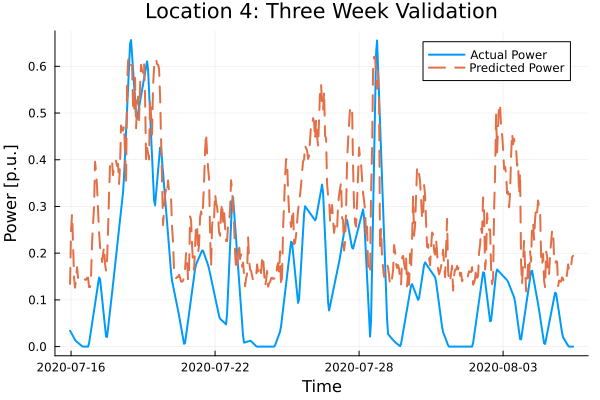

In [32]:
# Load validation data
validation_data = CSV.read("Location4.csv", DataFrame)

validation_data.Time = DateTime.(validation_data.Time)
validation_sort_index = sortperm(validation_data.Time)
validation_data = validation_data[validation_sort_index, :]

n_validation = min(504, nrow(validation_data))
start_index = rand(1:(nrow(validation_data) - n_validation + 1))
end_index = start_index + n_validation - 1

validation_time = validation_data.Time[start_index:end_index]
validation_power = Float64.(validation_data.Power[start_index:end_index])

validation_wind10 = Float64.(validation_data.windspeed_10m[start_index:end_index]) ./ 10.0
validation_wind100 = Float64.(validation_data.windspeed_100m[start_index:end_index]) ./ 10.0
validation_windgust = Float64.(validation_data.windgusts_10m[start_index:end_index]) ./ 10.0

Φ_validation_10 = zeros(n_validation, num_centers)
Φ_validation_100 = zeros(n_validation, num_centers)
Φ_validation_gust = zeros(n_validation, num_centers)

for i in 1:n_validation
    for j in 1:num_centers
        Φ_validation_10[i, j] = φ(validation_wind10[i], j)
        Φ_validation_100[i, j] = φ(validation_wind100[i], j)
        Φ_validation_gust[i, j] = φ(validation_windgust[i], j)
    end
end

validation_prediction =
    w_0 .+
    Φ_validation_10 * w_10 .+
    β_100 .* (Φ_validation_100 * w_100) .+
    β_windgust .* (Φ_validation_gust * w_gust)

validation_errors = validation_prediction .- validation_power

validation_RMSE = sqrt(mean(validation_errors.^2))

println()
println("======= VALIDATION PERFORMANCE =======")
println("Validation RMSE = ", validation_RMSE)
println("Validation period: ", validation_time[1], " to ", validation_time[end])
println("=====================================")

p_validation = plot(validation_time, validation_power, lw=2, label="Actual Power", xlabel="Time", ylabel="Power [p.u.]", title="Location 4: Three Week Validation")
plot!(p_validation, validation_time, validation_prediction, lw=2, linestyle=:dash, label="Predicted Power")

display(p_validation)

In [33]:
# Features:
# windspeed_10m, windspeed_100m, windgusts_10m,
# winddirection_10m, temperature_2m, relativehumidity_2m,
# dewpoint_2m, winddirection_100m

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

# Load three training datasets
data1 = CSV.read("Location1.csv", DataFrame)
data2 = CSV.read("Location2.csv", DataFrame)
data3 = CSV.read("Location3.csv", DataFrame)

data1.Time = DateTime.(data1.Time)
data2.Time = DateTime.(data2.Time)
data3.Time = DateTime.(data3.Time)

# Combine training datasets
data = vcat(data1, data2, data3)

n = nrow(data)
sort_index = sortperm(data.Time)

t = Float64.(data.Power[sort_index])

wind10_raw = Float64.(data.windspeed_10m[sort_index])
wind100_raw = Float64.(data.windspeed_100m[sort_index])
windgust_raw = Float64.(data.windgusts_10m[sort_index])

winddirection10_raw = Float64.(data.winddirection_10m[sort_index])
winddirection100_raw = Float64.(data.winddirection_100m[sort_index])

temperature_raw = Float64.(data.temperature_2m[sort_index])
humidity_raw = Float64.(data.relativehumidity_2m[sort_index])
dewpoint_raw = Float64.(data.dewpoint_2m[sort_index])

time = data.Time[sort_index]

# Normalize wind speed features
x = wind10_raw ./ 10.0
z = wind100_raw ./ 10.0
windgust = windgust_raw ./ 10.0

# Normalize additional features
temperature = temperature_raw ./ 30.0
humidity = humidity_raw ./ 100.0
dewpoint = dewpoint_raw ./ 30.0

# Circular transformation of wind direction
winddirection10_sin = sin.(2π .* winddirection10_raw ./ 360.0)
winddirection10_cos = cos.(2π .* winddirection10_raw ./ 360.0)

winddirection100_sin = sin.(2π .* winddirection100_raw ./ 360.0)
winddirection100_cos = cos.(2π .* winddirection100_raw ./ 360.0)

hour = Float64.(Dates.hour.(time))
hour_sin = sin.(2π .* hour ./ 24.0)
hour_cos = cos.(2π .* hour ./ 24.0)

α = 0.01
iter_max = 25_000
λ = 0.01
reg_type = "l2"

c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

# Gaussian RBF transformation
function φ(x_value, j)
    return exp(-(γ * abs(x_value - c[j]))^2)
end

Φ_10 = zeros(n, num_centers)
Φ_100 = zeros(n, num_centers)
Φ_gust = zeros(n, num_centers)

Φ_direction10_sin = zeros(n, num_centers)
Φ_direction10_cos = zeros(n, num_centers)

Φ_direction100_sin = zeros(n, num_centers)
Φ_direction100_cos = zeros(n, num_centers)

Φ_temperature = zeros(n, num_centers)
Φ_humidity = zeros(n, num_centers)
Φ_dewpoint = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers

        Φ_10[i, j] = φ(x[i], j)
        Φ_100[i, j] = φ(z[i], j)
        Φ_gust[i, j] = φ(windgust[i], j)

        # Circular wind direction
        Φ_direction10_sin[i, j] = φ(winddirection10_sin[i], j)
        Φ_direction10_cos[i, j] = φ(winddirection10_cos[i], j)

        Φ_direction100_sin[i, j] = φ(winddirection100_sin[i], j)
        Φ_direction100_cos[i, j] = φ(winddirection100_cos[i], j)

        # Weather features
        Φ_temperature[i, j] = φ(temperature[i], j)
        Φ_humidity[i, j] = φ(humidity[i], j)
        Φ_dewpoint[i, j] = φ(dewpoint[i], j)

    end
end

Random.seed!(128)

w_0 = rand()

# RBF weights
w_10 = rand(num_centers)
w_100 = rand(num_centers)
w_gust = rand(num_centers)

w_direction10_sin = rand(num_centers)
w_direction10_cos = rand(num_centers)

w_direction100_sin = rand(num_centers)
w_direction100_cos = rand(num_centers)

w_temperature = rand(num_centers)
w_humidity = rand(num_centers)
w_dewpoint = rand(num_centers)

# Feature weights
β_100 = rand()
β_windgust = rand()
β_direction10 = rand()
β_direction100 = rand()
β_temperature = rand()
β_humidity = rand()
β_dewpoint = rand()

# Stochastic gradient descent
for iteration in 1:iter_max

    i = rand(1:n)

    ϕ10_i = Φ_10[i, :]
    ϕ100_i = Φ_100[i, :]
    ϕgust_i = Φ_gust[i, :]

    ϕdirection10_sin_i = Φ_direction10_sin[i, :]
    ϕdirection10_cos_i = Φ_direction10_cos[i, :]

    ϕdirection100_sin_i = Φ_direction100_sin[i, :]
    ϕdirection100_cos_i = Φ_direction100_cos[i, :]

    ϕtemperature_i = Φ_temperature[i, :]
    ϕhumidity_i = Φ_humidity[i, :]
    ϕdewpoint_i = Φ_dewpoint[i, :]

    # RBF contributions
    f_10 = dot(ϕ10_i, w_10)
    f_100 = dot(ϕ100_i, w_100)
    f_gust = dot(ϕgust_i, w_gust)

    f_direction10_sin = dot(
        ϕdirection10_sin_i, w_direction10_sin)

    f_direction10_cos = dot(
        ϕdirection10_cos_i, w_direction10_cos)

    f_direction10 = f_direction10_sin + f_direction10_cos

    f_direction100_sin = dot(
        ϕdirection100_sin_i, w_direction100_sin)

    f_direction100_cos = dot(
        ϕdirection100_cos_i, w_direction100_cos)

    f_direction100 = f_direction100_sin + f_direction100_cos

    f_temperature = dot(ϕtemperature_i, w_temperature)
    f_humidity = dot(ϕhumidity_i, w_humidity)
    f_dewpoint = dot(ϕdewpoint_i, w_dewpoint)

    y_hat = w_0 +
            f_10 +
            β_100 * f_100 +
            β_windgust * f_gust +
            β_direction10 * f_direction10 +
            β_direction100 * f_direction100 +
            β_temperature * f_temperature +
            β_humidity * f_humidity +
            β_dewpoint * f_dewpoint

    error = y_hat - t[i]

    # Bias
    w_0 -= α * error

    # RBF weights: windspeed_10m
    for j in 1:num_centers
        w_10[j] -= α * error * ϕ10_i[j]
    end

    # RBF weights: windspeed_100m
    for j in 1:num_centers
        w_100[j] -= α * error * β_100 * ϕ100_i[j]
    end

    # RBF weights: windgusts_10m
    for j in 1:num_centers
        w_gust[j] -= α * error * β_windgust * ϕgust_i[j]
    end

    # RBF weights: winddirection_10m
    for j in 1:num_centers
        w_direction10_sin[j] -= α * error *
                                β_direction10 *
                                ϕdirection10_sin_i[j]

        w_direction10_cos[j] -= α * error *
                                β_direction10 *
                                ϕdirection10_cos_i[j]
    end

    # RBF weights: winddirection_100m
    for j in 1:num_centers
        w_direction100_sin[j] -= α * error *
                                 β_direction100 *
                                 ϕdirection100_sin_i[j]

        w_direction100_cos[j] -= α * error *
                                 β_direction100 *
                                 ϕdirection100_cos_i[j]
    end

    # RBF weights: temperature
    for j in 1:num_centers
        w_temperature[j] -= α * error *
                            β_temperature *
                            ϕtemperature_i[j]
    end

    # RBF weights: humidity
    for j in 1:num_centers
        w_humidity[j] -= α * error *
                         β_humidity *
                         ϕhumidity_i[j]
    end

    # RBF weights: dewpoint
    for j in 1:num_centers
        w_dewpoint[j] -= α * error *
                         β_dewpoint *
                         ϕdewpoint_i[j]
    end

    # Feature weights
    β_100 -= α * error * f_100
    β_windgust -= α * error * f_gust
    β_direction10 -= α * error * f_direction10
    β_direction100 -= α * error * f_direction100
    β_temperature -= α * error * f_temperature
    β_humidity -= α * error * f_humidity
    β_dewpoint -= α * error * f_dewpoint

    # Regularization
    if reg_type == "l2"

        w_10 .-= α * λ .* w_10
        w_100 .-= α * λ .* w_100
        w_gust .-= α * λ .* w_gust

        w_direction10_sin .-= α * λ .* w_direction10_sin
        w_direction10_cos .-= α * λ .* w_direction10_cos

        w_direction100_sin .-= α * λ .* w_direction100_sin
        w_direction100_cos .-= α * λ .* w_direction100_cos

        w_temperature .-= α * λ .* w_temperature
        w_humidity .-= α * λ .* w_humidity
        w_dewpoint .-= α * λ .* w_dewpoint

        β_100 -= α * λ * β_100
        β_windgust -= α * λ * β_windgust
        β_direction10 -= α * λ * β_direction10
        β_direction100 -= α * λ * β_direction100
        β_temperature -= α * λ * β_temperature
        β_humidity -= α * λ * β_humidity
        β_dewpoint -= α * λ * β_dewpoint

    elseif reg_type == "l1"

        w_10 .= sign.(w_10) .* max.(0, abs.(w_10) .- α * λ)
        w_100 .= sign.(w_100) .* max.(0, abs.(w_100) .- α * λ)
        w_gust .= sign.(w_gust) .* max.(0, abs.(w_gust) .- α * λ)

        w_direction10_sin .= sign.(w_direction10_sin) .* max.(
            0, abs.(w_direction10_sin) .- α * λ)

        w_direction10_cos .= sign.(w_direction10_cos) .* max.(
            0, abs.(w_direction10_cos) .- α * λ)

        w_direction100_sin .= sign.(w_direction100_sin) .* max.(
            0, abs.(w_direction100_sin) .- α * λ)

        w_direction100_cos .= sign.(w_direction100_cos) .* max.(
            0, abs.(w_direction100_cos) .- α * λ)

        w_temperature .= sign.(w_temperature) .* max.(
            0, abs.(w_temperature) .- α * λ)

        w_humidity .= sign.(w_humidity) .* max.(
            0, abs.(w_humidity) .- α * λ)

        w_dewpoint .= sign.(w_dewpoint) .* max.(
            0, abs.(w_dewpoint) .- α * λ)

        β_100 = sign(β_100) *
                max(0, abs(β_100) - α * λ)

        β_windgust = sign(β_windgust) *
                     max(0, abs(β_windgust) - α * λ)

        β_direction10 = sign(β_direction10) *
                        max(0, abs(β_direction10) - α * λ)

        β_direction100 = sign(β_direction100) *
                         max(0, abs(β_direction100) - α * λ)

        β_temperature = sign(β_temperature) *
                        max(0, abs(β_temperature) - α * λ)

        β_humidity = sign(β_humidity) *
                     max(0, abs(β_humidity) - α * λ)

        β_dewpoint = sign(β_dewpoint) *
                     max(0, abs(β_dewpoint) - α * λ)

    end
end

function w̅(
    x_value,
    z_value,
    windgust_value,
    winddirection10_value,
    temperature_value,
    humidity_value,
    dewpoint_value,
    winddirection100_value
)

    f_10 = sum(
        w_10[j] * φ(x_value, j)
        for j in 1:num_centers
    )

    f_100 = sum(
        w_100[j] * φ(z_value, j)
        for j in 1:num_centers
    )

    f_gust = sum(
        w_gust[j] * φ(windgust_value, j)
        for j in 1:num_centers
    )

    # Circular winddirection_10m
    direction10_sin = sin(
        2π * winddirection10_value / 360.0)

    direction10_cos = cos(
        2π * winddirection10_value / 360.0)

    f_direction10_sin = sum(
        w_direction10_sin[j] *
        φ(direction10_sin, j)
        for j in 1:num_centers
    )

    f_direction10_cos = sum(
        w_direction10_cos[j] *
        φ(direction10_cos, j)
        for j in 1:num_centers
    )

    f_direction10 = f_direction10_sin +
                    f_direction10_cos

    # Circular winddirection_100m
    direction100_sin = sin(
        2π * winddirection100_value / 360.0)

    direction100_cos = cos(
        2π * winddirection100_value / 360.0)

    f_direction100_sin = sum(
        w_direction100_sin[j] *
        φ(direction100_sin, j)
        for j in 1:num_centers
    )

    f_direction100_cos = sum(
        w_direction100_cos[j] *
        φ(direction100_cos, j)
        for j in 1:num_centers
    )

    f_direction100 = f_direction100_sin +
                     f_direction100_cos

    f_temperature = sum(
        w_temperature[j] * φ(temperature_value, j)
        for j in 1:num_centers
    )

    f_humidity = sum(
        w_humidity[j] * φ(humidity_value, j)
        for j in 1:num_centers
    )

    f_dewpoint = sum(
        w_dewpoint[j] * φ(dewpoint_value, j)
        for j in 1:num_centers
    )

    return w_0 +
           f_10 +
           β_100 * f_100 +
           β_windgust * f_gust +
           β_direction10 * f_direction10 +
           β_direction100 * f_direction100 +
           β_temperature * f_temperature +
           β_humidity * f_humidity +
           β_dewpoint * f_dewpoint
end

# Prediction
prediction = w_0 .+
             Φ_10 * w_10 .+
             β_100 .* (Φ_100 * w_100) .+
             β_windgust .* (Φ_gust * w_gust) .+
             β_direction10 .* (
                 Φ_direction10_sin * w_direction10_sin .+
                 Φ_direction10_cos * w_direction10_cos
             ) .+
             β_direction100 .* (
                 Φ_direction100_sin * w_direction100_sin .+
                 Φ_direction100_cos * w_direction100_cos
             ) .+
             β_temperature .* (Φ_temperature * w_temperature) .+
             β_humidity .* (Φ_humidity * w_humidity) .+
             β_dewpoint .* (Φ_dewpoint * w_dewpoint)

# Model performance
errors = prediction .- t

RMSE = sqrt(mean(errors.^2))
MAE = mean(abs.(errors))

println()
println("========== MODEL PERFORMANCE ==========")
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("β_100 = ", β_100)
println("β_windgust = ", β_windgust)
println("β_direction10 = ", β_direction10)
println("β_direction100 = ", β_direction100)
println("β_temperature = ", β_temperature)
println("β_humidity = ", β_humidity)
println("β_dewpoint = ", β_dewpoint)
println("=======================================")


========== MODEL PERFORMANCE ==========
RMSE = 0.20861397897870973
MAE  = 0.16690435935345418
β_100 = -0.3113673232245439
β_windgust = -0.248971323866708
β_direction10 = -0.06657202888877539
β_direction100 = -0.03842321137817693
β_temperature = 0.04334476802540029
β_humidity = -0.055742195003585564
β_dewpoint = 0.08201656688438036



======= VALIDATION PERFORMANCE =======
Validation RMSE = 0.20173843488076468
Validation period: 2019-02-06T15:00:00 to 2019-02-27T14:00:00


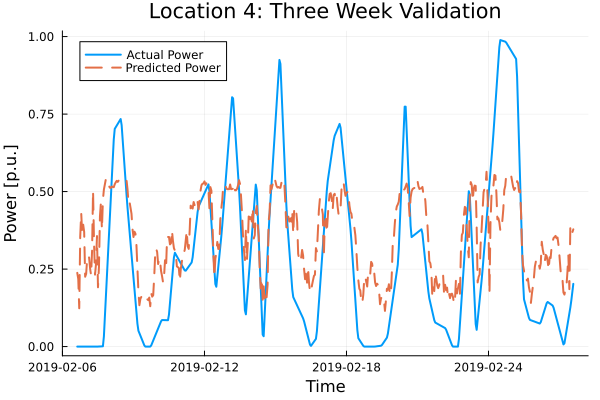

In [41]:
# Load validation data
validation_data = CSV.read("Location4.csv", DataFrame)

validation_data.Time = DateTime.(validation_data.Time)
validation_sort_index = sortperm(validation_data.Time)
validation_data = validation_data[validation_sort_index, :]

n_validation = min(504, nrow(validation_data))
start_index = rand(1:(nrow(validation_data) - n_validation + 1))
end_index = start_index + n_validation - 1

validation_time = validation_data.Time[start_index:end_index]
validation_power = Float64.(validation_data.Power[start_index:end_index])

validation_wind10 = Float64.(validation_data.windspeed_10m[start_index:end_index]) ./ 10.0
validation_wind100 = Float64.(validation_data.windspeed_100m[start_index:end_index]) ./ 10.0
validation_windgust = Float64.(validation_data.windgusts_10m[start_index:end_index]) ./ 10.0

Φ_validation_10 = zeros(n_validation, num_centers)
Φ_validation_100 = zeros(n_validation, num_centers)
Φ_validation_gust = zeros(n_validation, num_centers)

for i in 1:n_validation
    for j in 1:num_centers
        Φ_validation_10[i, j] = φ(validation_wind10[i], j)
        Φ_validation_100[i, j] = φ(validation_wind100[i], j)
        Φ_validation_gust[i, j] = φ(validation_windgust[i], j)
    end
end

validation_prediction =
    w_0 .+
    Φ_validation_10 * w_10 .+
    β_100 .* (Φ_validation_100 * w_100) .+
    β_windgust .* (Φ_validation_gust * w_gust)

validation_errors = validation_prediction .- validation_power

validation_RMSE = sqrt(mean(validation_errors.^2))

println()
println("======= VALIDATION PERFORMANCE =======")
println("Validation RMSE = ", validation_RMSE)
println("Validation period: ", validation_time[1], " to ", validation_time[end])
println("=====================================")

p_validation = plot(validation_time, validation_power, lw=2, label="Actual Power", xlabel="Time", ylabel="Power [p.u.]", title="Location 4: Three Week Validation")
plot!(p_validation, validation_time, validation_prediction, lw=2, linestyle=:dash, label="Predicted Power")

display(p_validation)